In [1]:
import utils.biosensor_mc_analysis
import importlib
importlib.reload(utils.biosensor_mc_analysis)

<module 'utils.biosensor_mc_analysis' from '/Users/rynon/Documents/GitHub/SensorModeling/utils/biosensor_mc_analysis.py'>

In [2]:
import matplotlib as mpl
import seaborn as sns

# Seaborn theme
sns.set_theme(
    style="ticks",        # "white", "whitegrid", "ticks", "darkgrid"
    context="paper",       # notebook, paper, talk, poster
    palette="deep"
)

# Your publication formatting
mpl.rcParams.update({

    # Fonts
    "font.family": "Arial",
    "font.size": 24,

    # Figure titles
    "figure.titlesize": 34,
    "figure.titleweight": "bold",

    # Axes titles/labels
    "axes.titlesize": 14,
    "axes.labelsize": 14,

    # Tick labels
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,

    # Legend
    "legend.fontsize": 16,
    "legend.title_fontsize": 18,

    # Lines & markers
    "lines.linewidth": 3,
    "lines.markersize": 8,

    # Axes
    "axes.linewidth": 2,

    # Ticks
    "xtick.major.size": 8,
    "ytick.major.size": 8,
    "xtick.major.width": 2,
    "ytick.major.width": 2,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,
    "xtick.minor.width": 1.5,
    "ytick.minor.width": 1.5,

    # Grid
    "grid.linewidth": 1,
    "grid.alpha": 0.3,

    # Export
    "figure.dpi": 150,
    "savefig.dpi": 600,

    # Editable vector graphics
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

,phase_index,phase_label,value_column,n_points,fit_success,fit_message,phase_start_t_s,phase_end_t_s,phase_duration_s,direction,...,y_inf_se,amplitude,k_eff_s_inv,k_eff_se_s_inv,tau_eff_s,tau_eff_se_s,half_time_s,half_time_se_s,r_squared,rmse
0,0,association_1nM,theta,202,True,ok,0.0,200.000001,200.000001,increasing,...,0.001762,-0.088241,0.025183,0.001907,39.709707,3.006934,27.524671,2.084248,0.624917,0.013769


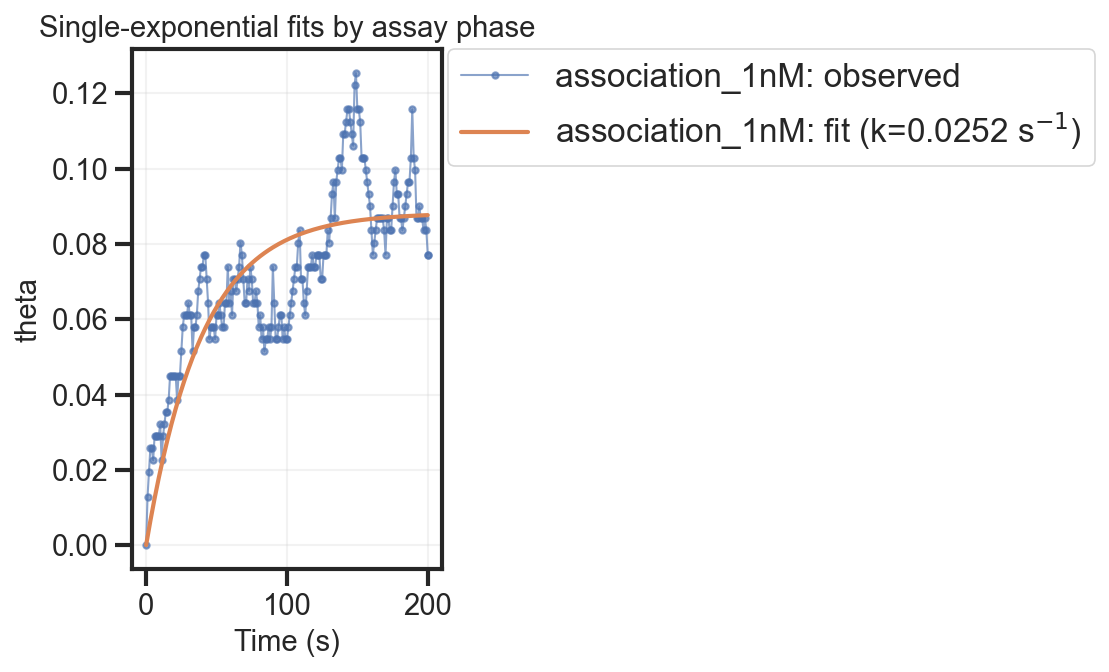

In [3]:
from utils.biosensor_mc_analysis import (
    fit_history_phases,
    plot_phase_exponential_fits,
)

run_directory = "data/simulations/260806_soloNanopore_50nm_kon1e6_koff-1_10nM_200s"

fits, fitted_history = fit_history_phases(
    run_directory,
    value_column="theta",
    value_bounds=(0.0, 1.0),
)

display(fits)

fig, ax = plot_phase_exponential_fits(
    run_directory,
    fits=fits,
    fitted_history=fitted_history,
    value_column="theta",
)

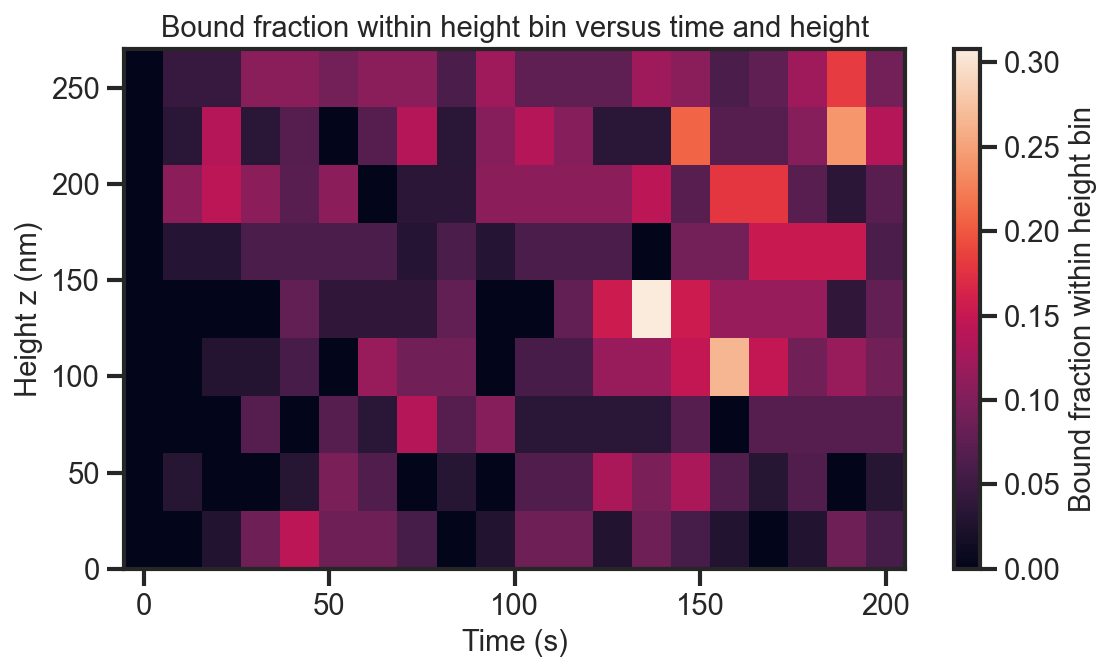

In [8]:
from utils.biosensor_mc_analysis import (
    calculate_height_profile_matrix,
    plot_height_profile_heatmap,
)

profile = calculate_height_profile_matrix(
    run_directory,
    metric="bound_receptor_fraction",
    bin_width_m=30e-9,
    coordinate="z",
)

fig, ax, profile = plot_height_profile_heatmap(
    profile,
    vertical_units="nm",
)

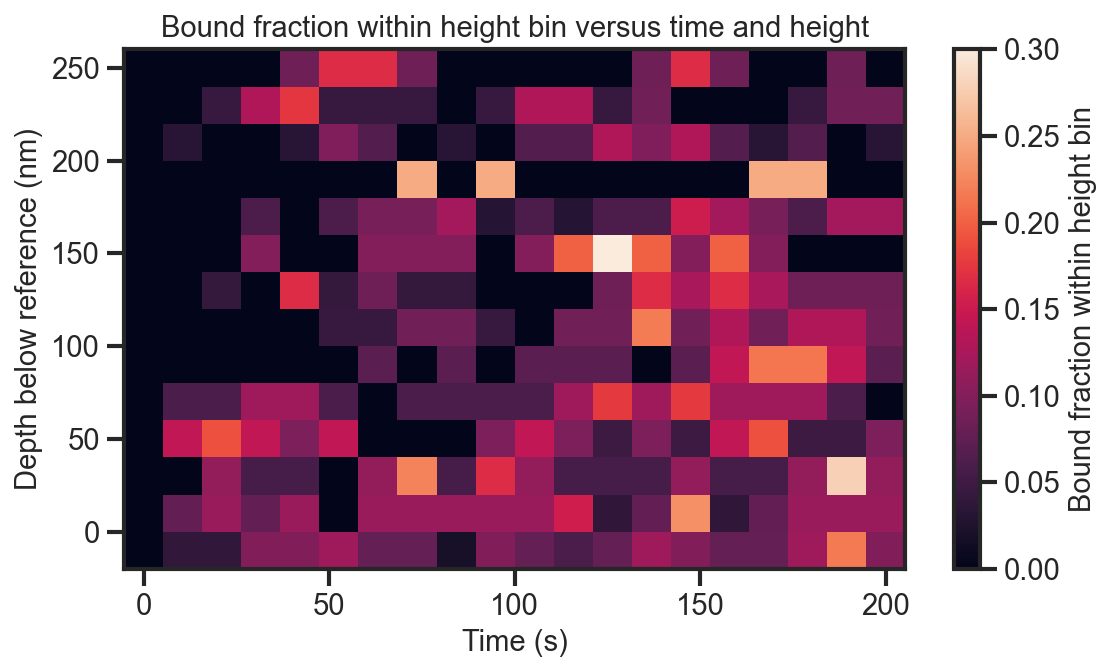

In [5]:
rim_z_m = 250e-9

depth_profile = calculate_height_profile_matrix(
    run_directory,
    metric="bound_receptor_fraction",
    bin_width_m=20e-9,
    coordinate="depth",
    reference_z_m=rim_z_m,
)

fig, ax, depth_profile = plot_height_profile_heatmap(
    depth_profile,
    vertical_units="nm",
)

In [6]:
from utils.biosensor_mc_analysis import (
    calculate_bound_height_metrics,
    plot_bound_height_metrics,
)

penetration_metrics = calculate_bound_height_metrics(
    run_directory,
    reference_z_m=100e-9,
    deep_region_depth_m=60e-9,
)

display(penetration_metrics)

,frame_index,t_s,phase_label,n_bound,n_receptors,theta,mean_bound_z_m,median_bound_z_m,std_bound_z_m,min_bound_z_m,max_bound_z_m,bound_z_q10_m,bound_z_q90_m,mean_bound_depth_m,median_bound_depth_m,max_bound_depth_m,bound_depth_q90_m,fraction_bound_below_reference,fraction_bound_in_deep_region
0,0,0.000000,association_1nM,0,311,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,10.526315,association_1nM,9,311,0.028939,1.977778e-07,2.000000e-07,6.245492e-08,4.000000e-08,2.550000e-07,1.440000e-07,2.550000e-07,-9.777778e-08,-1.000000e-07,6.000000e-08,-4.400000e-08,0.111111,0.111111
2,2,21.052630,association_1nM,14,311,0.045016,1.950000e-07,2.100000e-07,6.065123e-08,2.000000e-08,2.550000e-07,1.280000e-07,2.505000e-07,-9.500000e-08,-1.100000e-07,8.000000e-08,-2.800000e-08,0.071429,0.071429
3,3,31.578947,association_1nM,19,311,0.061093,1.676316e-07,1.900000e-07,8.666889e-08,1.000000e-08,2.550000e-07,2.000000e-08,2.550000e-07,-6.763158e-08,-9.000000e-08,9.000000e-08,8.000000e-08,0.263158,0.157895
4,4,42.105262,association_1nM,23,311,0.073955,1.521739e-07,1.700000e-07,9.281616e-08,5.000000e-09,2.550000e-07,2.000000e-08,2.550000e-07,-5.217391e-08,-7.000000e-08,9.500000e-08,8.000000e-08,0.260870,0.260870
5,5,52.631579,association_1nM,20,311,0.064309,1.410000e-07,1.600000e-07,9.596353e-08,5.000000e-09,2.550000e-07,1.850000e-08,2.550000e-07,-4.100000e-08,-6.000000e-08,9.500000e-08,8.150000e-08,0.400000,0.300000
6,6,63.157894,association_1nM,22,311,0.070740,1.440909e-07,1.350000e-07,9.099995e-08,5.000000e-09,2.550000e-07,2.100000e-08,2.550000e-07,-4.409091e-08,-3.500000e-08,9.500000e-08,7.900000e-08,0.363636,0.227273
7,7,73.684210,association_1nM,23,311,0.073955,1.597826e-07,1.800000e-07,8.449953e-08,5.000000e-09,2.550000e-07,6.000000e-08,2.550000e-07,-5.978261e-08,-8.000000e-08,9.500000e-08,4.000000e-08,0.304348,0.086957
8,8,84.210525,association_1nM,16,311,0.051447,1.515625e-07,1.400000e-07,7.043878e-08,4.000000e-08,2.550000e-07,7.500000e-08,2.500000e-07,-5.156250e-08,-4.000000e-08,6.000000e-08,2.500000e-08,0.312500,0.062500
9,9,94.736842,association_1nM,19,311,0.061093,1.892105e-07,2.200000e-07,7.674742e-08,2.000000e-08,2.550000e-07,6.000000e-08,2.550000e-07,-8.921053e-08,-1.200000e-07,8.000000e-08,4.000000e-08,0.210526,0.052632


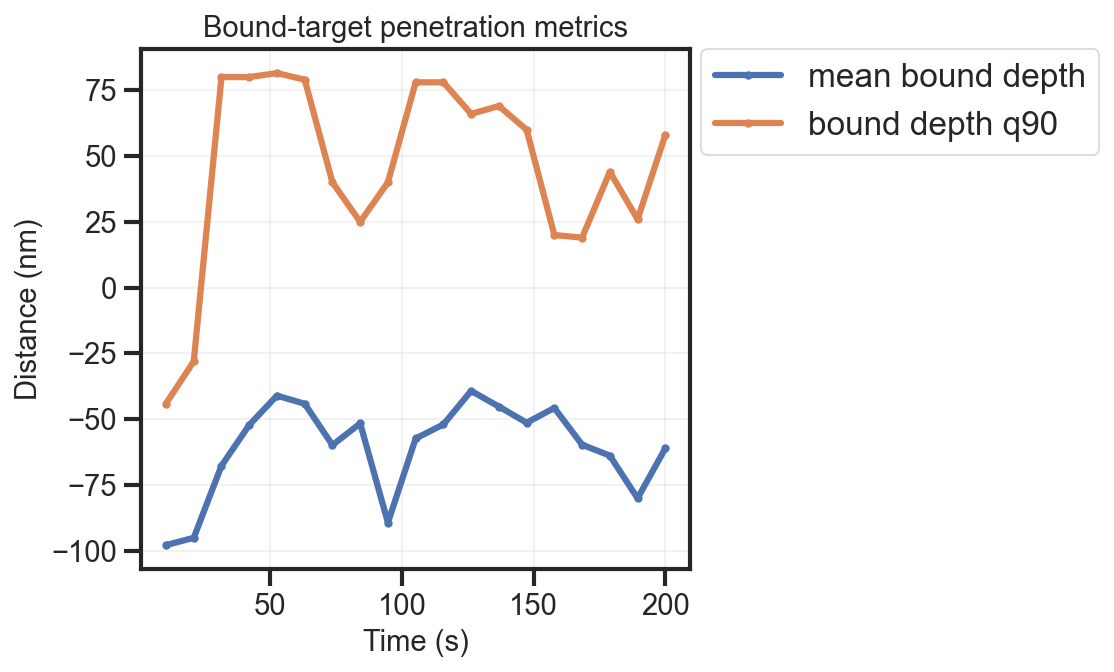

In [7]:
fig, ax = plot_bound_height_metrics(
    penetration_metrics,
    columns=[
        "mean_bound_depth_m",
        "bound_depth_q90_m",
    ],
    distance_units="nm",
)